# Задание 1: Базовая работа с изображением

# 1. Загрузите изображение в оттенках серого sar_1_gray.jpg. 
# 2. постройте гистограмму
# 3. реализуйте алгоритм гамма коррекции с параметром гамма <1, >1.
# 4. Сравните исходное изображение, скорректированное при помощи гамма-фильтра. MSE, SSIM.
# 5. реализуйте алгоритм статистической цветокоррекции на основе статистики eq_gray.
# 6. Протестируйте работу алгоритмов пороговой фильтрации с различными параметрами.
# Для каждого решения - напечатайте результат

In [41]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.metrics import structural_similarity as ssim, mean_squared_error

In [42]:
image_path = Path("first_lab") / "sar_1_gray.jpg"

if not image_path.exists():
    image_path = Path("sar_1_gray.jpg")

img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

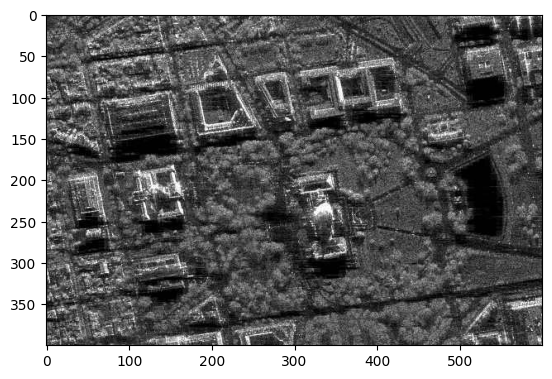

In [43]:
plt.imshow(img, cmap='gray')

## Гистограмма

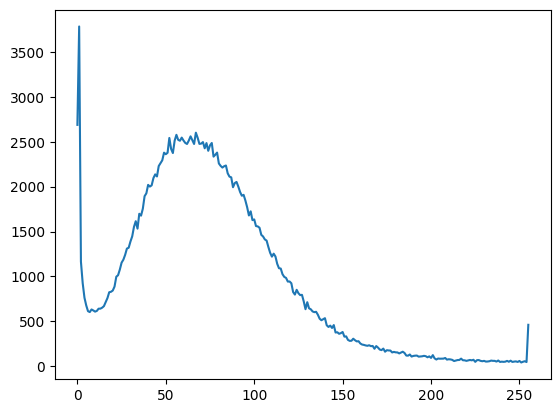

In [44]:
histSize = 256
histRange = (0, 256)
accumulate = False #вычисляем заново

b_hist = cv2.calcHist([img], [0], None, [histSize], histRange, accumulate=accumulate)
plt.plot(b_hist)

In [45]:
b_hist_cum = b_hist.cumsum() #кумулятивная сумма

Text(0, 0.5, 'Количество пикселей')

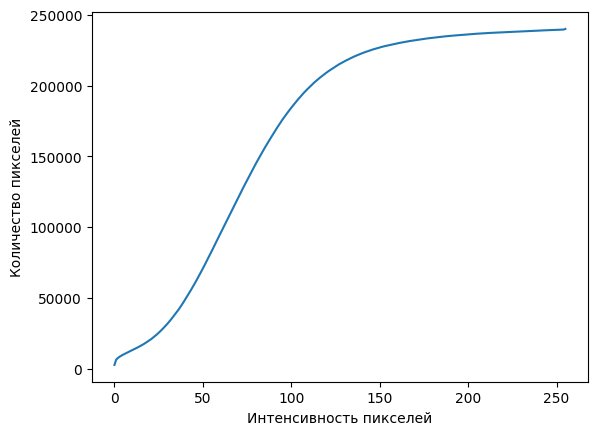

In [46]:
plt.plot(b_hist_cum)
plt.xlabel('Интенсивность пикселей')
plt.ylabel('Количество пикселей')

## Гамма-коррекция

In [47]:
plt.figure(figsize=(22, 6))

<Figure size 2200x600 with 0 Axes>

<Figure size 2200x600 with 0 Axes>

In [48]:
gamma1 = 0.2

MSE: 14018.0529
SSIM: 0.5017


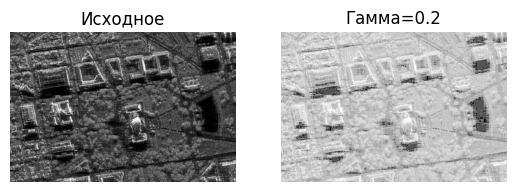

In [49]:
gamma_corrected = np.array(255 * (img / 255.0) ** gamma1, dtype='uint8')

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title("Исходное")
plt.axis('off')

mse_value = mean_squared_error(img, gamma_corrected) #средняяквадратичная ошибка

ssim_value, _ = ssim(img, gamma_corrected, full=True, win_size=3) #структурное сходство

print(f"MSE: {mse_value:.4f}")
print(f"SSIM: {ssim_value:.4f}")

plt.subplot(1,2,2)
plt.imshow(gamma_corrected, cmap='gray')
plt.title(f"Гамма={gamma1}")
plt.axis('off')

plt.show()

In [50]:
gamma1 = 2.7

MSE: 3937.9684
SSIM: 0.2564


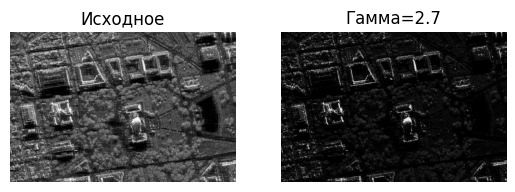

In [51]:
gamma_corrected = np.array(255 * (img / 255.0) ** gamma1, dtype='uint8')

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title("Исходное")
plt.axis('off')

mse_value1 = mean_squared_error(img, gamma_corrected)

ssim_value1, _ = ssim(img, gamma_corrected, full=True, win_size=3)

print(f"MSE: {mse_value1:.4f}")
print(f"SSIM: {ssim_value1:.4f}")

plt.subplot(1,2,2)
plt.imshow(gamma_corrected, cmap='gray')
plt.title(f"Гамма={gamma1}")
plt.axis('off')

plt.show()

## Статистическая цветокоррекция

In [52]:
img_gray = img 

mean = img_gray.mean()
std = img_gray.std()

# eq_gray = cv2.equalizeHist(img_gray)
# эквализация гистограммы собственная реализация
hist_eq = np.bincount(img_gray.ravel(), minlength=256)
cdf = hist_eq.cumsum()
cdf_min = cdf[cdf > 0][0]
lut = np.round((cdf - cdf_min) / (img_gray.size - cdf_min) * 255)
lut = np.clip(lut, 0, 255).astype(np.uint8)
eq_gray = lut[img_gray]

mean_eq_gray = eq_gray.mean()
std_eq_gray  = eq_gray.std()

# Статистическая цветокоррекция собственная реализация
corrected_img = mean_eq_gray + (img_gray.astype(np.float32)- mean) * (std_eq_gray / std)
corrected_img = np.clip(corrected_img, 0, 255).astype(np.uint8)
mean_cor = corrected_img.mean()
std_cor  = corrected_img.std()

Text(0.5, 1.0, 'Коррекция\nmean: 123.1, std: 65.3')

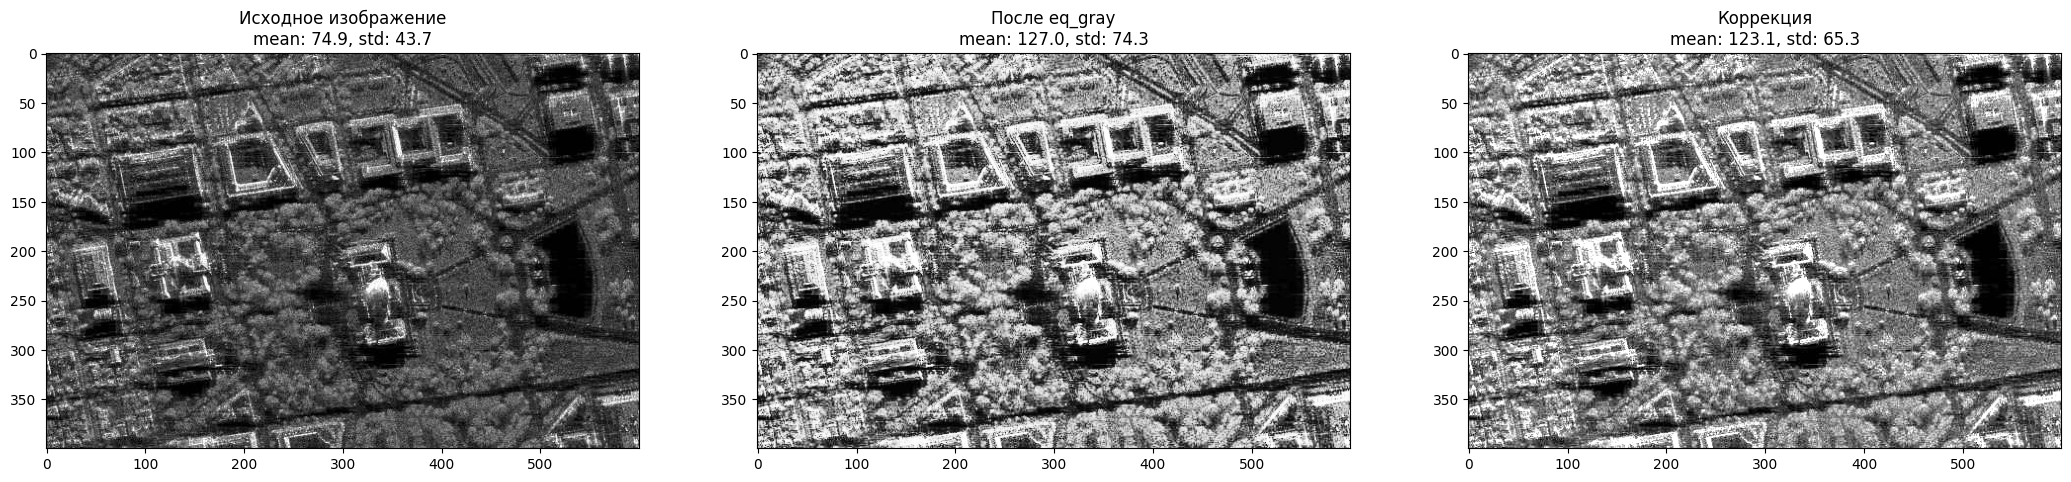

In [53]:
plt.figure(figsize=(26, 6))
plt.subplot(1,3,1)
plt.imshow(img_gray, cmap='gray')
plt.title(f'Исходное изображение\nmean: {mean:.1f}, std: {std:.1f}')
plt.subplot(1,3,2)
plt.imshow(eq_gray, cmap="gray")
plt.title(f'После eq_gray\nmean: {mean_eq_gray:.1f}, std: {std_eq_gray:.1f}')
plt.subplot(1,3,3)
plt.imshow(corrected_img, cmap='gray')
plt.title(f'Коррекция\nmean: {mean_cor:.1f}, std: {std_cor:.1f}')

## Пороговая фильтрация

In [54]:
_,thresh1 = cv2.threshold(img_gray,60,255,cv2.THRESH_BINARY)
_,thresh2 = cv2.threshold(img_gray,150,255,cv2.THRESH_BINARY)
_,thresh3 = cv2.threshold(img_gray,254,255,cv2.THRESH_BINARY)

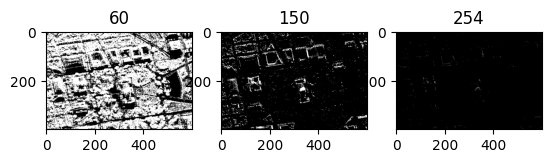

In [55]:
plt.subplot(1,3,1)
plt.title("60")
plt.imshow(thresh1, cmap='gray')

plt.subplot(1,3,2)
plt.title("150")
plt.imshow(thresh2, cmap='gray')

plt.subplot(1,3,3)
plt.title("254")
plt.imshow(thresh3, cmap='gray')

plt.show()